In [106]:
# Negative-binomial forecasting of monthly intake counts per ZIP

In [107]:
import re
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
 
CSV_FILENAMES = ["long_beach_california_cats_with_tnr_all_years_2.csv",
                 "long_beach_california_cats_with_tnr_all_years.csv"]
# The 11 highest-volume Long Beach zips. Defined independently of household data
# so a zip is never dropped just because a household count is missing.
TARGET_ZIPS = ["90802", "90803", "90804", "90805", "90806", "90807",
               "90808", "90810", "90813", "90814", "90815"]
 
# Household counts are ONLY used for the after-the-fact feral estimate (Cell 8).
# 90806 is missing, so fill it in when you have it (None = no estimate for that zip).
HOUSEHOLDS = {
    "90802": 22421, "90803": 16894, "90804": 15290, "90805": 28213,
    "90806": 12586,                     # <-- add the household count here
    "90807": 12636, "90808": 14198, "90810": 9956, "90813": 17252,
    "90814": 9167, "90815": 15432,
}
FERAL_HOUSEHOLD_RATE = 0.07            # share of households that feed community cats
CATS_PER_FEEDING_HOUSEHOLD = 3.2       # from the research study you're using
 
VALID_INTAKES = ["STRAY", "TRAP, NEUTER, RETURN", "TRAP, NEUTER, RELEASE"]
FIRST_YEAR = 2017
MAX_FILL_KM = 0.5                      # lat/lon fill only if a known-zip intake is this close
K_NEIGHBORS = 5
 

In [108]:
for fname in CSV_FILENAMES:
    try:
        df = pd.read_csv(fname, low_memory=False)
        print("Loaded", fname)
        break
    except FileNotFoundError:
        continue
else:
    raise FileNotFoundError(f"None of {CSV_FILENAMES} found")
 
df.columns = [c.lower().strip() for c in df.columns]

Loaded long_beach_california_cats_with_tnr_all_years.csv


In [109]:
def zip_from_address(s: pd.Series) -> pd.Series:
    """Trailing 5-character zip (optionally ZIP+4) at the END of the address.
    Fixes letter-O typos like '908O5'. Only accepts CA-style zips (90000-96999),
    so junk such as '13300' becomes NaN and gets filled from coordinates instead."""
    t = s.astype(str).str.upper().str.strip()
    tok = t.str.extract(r"\b([0-9O]{5})(?:-\d{4})?\s*$")[0].str.replace("O", "0", regex=False)
    return tok.where(tok.str.fullmatch(r"9[0-6]\d{3}", na=False))
 
 
df["zip_addr"] = zip_from_address(df["crossing"])

In [110]:

def _xy_km(lat, lon, lat0=33.8):
    return np.column_stack([np.asarray(lat) * 110.57,
                            np.asarray(lon) * 111.32 * np.cos(np.radians(lat0))])
 
 
known = df["zip_addr"].notna() & df["latitude"].notna() & df["longitude"].notna()
need = df["zip_addr"].isna() & df["latitude"].notna() & df["longitude"].notna()
 
# Reference points come from the WHOLE file (all zips), so a cat found just outside
# the 11 target zips is matched to its real zip and then filtered out, not forced in.
ref_xy = _xy_km(df.loc[known, "latitude"], df.loc[known, "longitude"])
ref_zip = df.loc[known, "zip_addr"].values
tree = cKDTree(ref_xy)
 
 
def vote_zip(xy, k=K_NEIGHBORS, max_km=MAX_FILL_KM, skip_same_point=False):
    dist, idx = tree.query(xy, k=k + 25 if skip_same_point else k)
    out = []
    for d, i in zip(dist, idx):
        if skip_same_point:                      # validation only: ignore identical coordinates
            keep = d > 1e-9
            d, i = d[keep][:k], i[keep][:k]
        d, i = np.atleast_1d(d), np.atleast_1d(i)
        if len(d) == 0 or d.min() > max_km:
            out.append(np.nan)
            continue
        zs = ref_zip[i[d <= max_km]]
        vals, cnt = np.unique(zs, return_counts=True)
        out.append(vals[cnt.argmax()])
    return np.array(out, dtype=object)
 
 
# Sanity check: how well does the fill recover zips we already know?
# (identical coordinates are excluded, so this is a conservative estimate)
rng = np.random.default_rng(0)
sample = rng.choice(len(ref_xy), size=min(2000, len(ref_xy)), replace=False)
pred = vote_zip(ref_xy[sample], skip_same_point=True)
truth = ref_zip[sample]
answered = pd.notna(pred)
print(f"Fill validation: answered {answered.mean():.1%} of held-out rows, "
      f"correct on {np.mean(pred[answered] == truth[answered]):.1%} of those")
 
# Apply the fill
df["zip_code"] = df["zip_addr"]
fill_xy = _xy_km(df.loc[need, "latitude"], df.loc[need, "longitude"])
df.loc[need, "zip_code"] = vote_zip(fill_xy)
print(f"ZIP source: address {df['zip_addr'].notna().sum():,} | "
      f"filled from lat/lon {(df['zip_code'].notna() & df['zip_addr'].isna()).sum():,} | "
      f"still missing {df['zip_code'].isna().sum():,}")

Fill validation: answered 91.1% of held-out rows, correct on 93.4% of those
ZIP source: address 24,564 | filled from lat/lon 2,821 | still missing 33


In [111]:
df["intake_type"] = df["intake_type"].astype(str).str.upper().str.strip()
df["intake_date"] = pd.to_datetime(df["intake_date"], errors="coerce")
 
df_filtered = df[
    df["intake_type"].isin(VALID_INTAKES)
    & df["zip_code"].isin(TARGET_ZIPS)
    & (df["intake_date"].dt.year >= FIRST_YEAR)
].dropna(subset=["zip_code", "intake_date", "intake_type"]).copy()
# outcome columns are deliberately NOT required or filtered on: an intake is an
# intake whether the cat was adopted, euthanized, or is still in the shelter.
 
df_filtered["year_month"] = df_filtered["intake_date"].dt.to_period("M").astype(str)
print(f"{len(df_filtered):,} intakes across {df_filtered['zip_code'].nunique()} zips")
 
 
# %% Cell 6: monthly summary for the model (complete grid, zeros included)
months = pd.period_range(f"{FIRST_YEAR}-01", df_filtered["intake_date"].max().to_period("M"), freq="M")
grid = pd.MultiIndex.from_product([TARGET_ZIPS, months.astype(str)], names=["zip_code", "year_month"])
monthly_summary = (df_filtered.groupby(["zip_code", "year_month"]).size()
                   .reindex(grid, fill_value=0).rename("cat_count").reset_index())
print(monthly_summary.head(12).to_string(index=False))

21,510 intakes across 11 zips
zip_code year_month  cat_count
   90802    2017-01          7
   90802    2017-02          9
   90802    2017-03          6
   90802    2017-04         20
   90802    2017-05          5
   90802    2017-06         20
   90802    2017-07         23
   90802    2017-08         15
   90802    2017-09         16
   90802    2017-10          6
   90802    2017-11          8
   90802    2017-12          6


In [112]:
pivot_counts = monthly_summary.pivot(index="zip_code", columns="year_month", values="cat_count")
try:
    display(pivot_counts)          # Jupyter
except NameError:
    print(pivot_counts)

year_month,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,...,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
zip_code,,,,,,,,,,,,,,,,,,,,,
90802,7,9,6,20,5,20,23,15,16,6,...,4,1,2,13,15,22,13,7,4,1
90803,4,1,3,0,4,2,9,15,5,2,...,0,1,5,3,4,1,1,10,2,0
90804,7,9,7,17,18,28,26,35,13,20,...,5,4,10,5,32,24,22,5,8,1
90805,34,31,40,87,130,110,107,51,81,77,...,17,27,44,57,64,75,55,75,57,40
90806,2,8,10,29,30,61,34,22,20,27,...,26,7,11,33,54,29,34,19,32,17
90807,4,0,16,11,11,10,18,21,10,14,...,7,6,10,14,16,12,3,6,9,2
90808,5,4,8,12,5,22,19,15,16,13,...,5,6,14,22,21,16,19,9,11,2
90810,2,3,22,32,34,24,19,33,34,23,...,8,15,6,46,38,31,8,5,19,7
90813,17,13,19,60,84,69,52,55,71,49,...,19,37,33,58,31,36,37,24,28,14


In [113]:
zip_info = pd.DataFrame({"households": pd.Series(HOUSEHOLDS)}).reindex(TARGET_ZIPS)
zip_info["estimated_feral_cats"] = (zip_info["households"]
                                    * FERAL_HOUSEHOLD_RATE * CATS_PER_FEEDING_HOUSEHOLD).round(0)
 
# Example use: recent full-year intakes per 1,000 estimated feral cats
last_full_year = df_filtered["intake_date"].dt.year.max() - 1
yearly = (df_filtered[df_filtered["intake_date"].dt.year == last_full_year]
          .groupby("zip_code").size().rename(f"intakes_{last_full_year}"))
zip_info = zip_info.join(yearly)
zip_info["intakes_per_1000_est_feral"] = (1000 * zip_info[f"intakes_{last_full_year}"]
                                          / zip_info["estimated_feral_cats"]).round(1)
print(zip_info)

       households  estimated_feral_cats  intakes_2025  \
90802       22421                5022.0           121   
90803       16894                3784.0            71   
90804       15290                3425.0           157   
90805       28213                6320.0           656   
90806       12586                2819.0           326   
90807       12636                2830.0           166   
90808       14198                3180.0           109   
90810        9956                2230.0           192   
90813       17252                3864.0           421   
90814        9167                2053.0            43   
90815       15432                3457.0           179   

       intakes_per_1000_est_feral  
90802                        24.1  
90803                        18.8  
90804                        45.8  
90805                       103.8  
90806                       115.6  
90807                        58.7  
90808                        34.3  
90810                      

In [114]:
import warnings
import numpy as np
import pandas as pd
from scipy.stats import nbinom
 
warnings.filterwarnings("ignore")
 
LAST_FULL_MONTH = "2026-09"   # the current month is partial, so drop it
N_TEST_ORIGINS = 24           # how many monthly forecast origins to backtest

In [115]:
def build_counts(df_filtered, start="2017-01", end=LAST_FULL_MONTH):
    c = df_filtered.groupby(["year_month", "zip_code"]).size().unstack("zip_code")
    c.index = pd.PeriodIndex(c.index, freq="M")
    full = pd.period_range(start, end, freq="M")
    return c.reindex(full).fillna(0).astype(int)      # months x zips

In [116]:
FEATS = ["lag0", "lag1", "roll3", "roll12", "seas",
         "sin1", "cos1", "sin2", "cos2", "covid"]
 
 
def build_panel(counts, h=1):
    frames = []
    for z in counts.columns:
        s = counts[z].astype(float)
        f = pd.DataFrame({"zip": z}, index=counts.index)
        f["origin"] = counts.index                      # last month we know
        f["target_period"] = counts.index + h           # month being predicted
        f["y"] = s.shift(-h)                            # NaN on forecast rows
        f["lag0"] = np.log1p(s)
        f["lag1"] = np.log1p(s.shift(1))
        f["roll3"] = np.log1p(s.rolling(3).mean())
        f["roll12"] = np.log1p(s.rolling(12).mean())
        f["seas"] = np.log1p(s.shift(12 - h))           # target month, a year earlier
        f["naive"] = s.shift(12 - h)                    # seasonal-naive baseline
        frames.append(f)
    P = pd.concat(frames, ignore_index=True)
    mon = P["target_period"].dt.month
    for k in (1, 2):
        P[f"sin{k}"] = np.sin(2 * np.pi * k * mon / 12)
        P[f"cos{k}"] = np.cos(2 * np.pi * k * mon / 12)
    P["covid"] = ((P["target_period"] >= pd.Period("2020-03", "M")) &
                  (P["target_period"] <= pd.Period("2020-12", "M"))).astype(int)
    return P.dropna(subset=["lag0", "lag1", "roll3", "roll12", "seas"])
 
 
def design(P, zips):
    X = pd.get_dummies(P["zip"]).reindex(columns=zips, fill_value=0).astype(float)
    X[FEATS] = P[FEATS].values
    return X                                            # one dummy per ZIP, no constant

In [117]:
def _irls(X, y, alpha=None, max_iter=100, tol=1e-9, ridge=1e-8):
    """Iteratively reweighted least squares. alpha=None -> Poisson; else NB2 with fixed alpha
    (variance = mu + alpha * mu^2)."""
    mu = (y + y.mean()) / 2 + 0.1
    eta = np.log(mu)
    beta = np.zeros(X.shape[1])
    for _ in range(max_iter):
        var = mu if alpha is None else mu + alpha * mu ** 2
        w = mu ** 2 / var
        z = eta + (y - mu) / mu
        XtW = X.T * w
        beta_new = np.linalg.solve(XtW @ X + ridge * np.eye(X.shape[1]), XtW @ z)
        eta = np.clip(X @ beta_new, -20, 20)
        mu = np.exp(eta)
        done = np.max(np.abs(beta_new - beta)) < tol
        beta = beta_new
        if done:
            break
    return beta, mu
 
 
class NBModel:
    def __init__(self, beta, cols):
        self.beta, self.cols = beta, cols
 
    def predict(self, X):
        eta = np.clip(X[self.cols].to_numpy(float) @ self.beta, -20, 20)
        return pd.Series(np.exp(eta), index=X.index)
 
 
def fit_nb(X, y, n_iter=2):
    """Poisson fit -> moment estimate of alpha -> NB refit (repeated n_iter times).
    Alpha is re-estimated on whatever training window you pass in."""
    Xv, yv = X.to_numpy(float), np.asarray(y, float)
    beta, mu = _irls(Xv, yv)
    for _ in range(n_iter):
        alpha = max(((yv - mu) ** 2 - mu).sum() / (mu ** 2).sum(), 1e-4)
        beta, mu = _irls(Xv, yv, alpha=alpha)
    return NBModel(beta, list(X.columns)), alpha
 
 
def nb_params(mu, alpha):
    r = 1.0 / alpha
    return r, r / (r + mu)
 
 
def nb_interval(mu, alpha, lo_q=0.10, hi_q=0.90):
    r, p = nb_params(mu, alpha)
    return nbinom.ppf(lo_q, r, p), nbinom.ppf(hi_q, r, p)

In [118]:
def backtest(counts, h=1, n_origins=N_TEST_ORIGINS):
    P = build_panel(counts, h)
    zips = list(counts.columns)
    known = P.dropna(subset=["y"])
    origins = sorted(known["origin"].unique())[-n_origins:]
    out = []
    for o in origins:
        train = known[known["target_period"] <= o]     # only targets already observed at o
        test = known[known["origin"] == o]
        model, alpha = fit_nb(design(train, zips), train["y"])
        mu = model.predict(design(test, zips)).values
        lo, hi = nb_interval(mu, alpha)
        r, p = nb_params(mu, alpha)
        out.append(pd.DataFrame({
            "zip": test["zip"].values, "origin": o, "y": test["y"].values,
            "nb": mu, "lo80": lo, "hi80": hi, "naive": test["naive"].values,
            "logloss": -nbinom.logpmf(test["y"].values, r, p), "alpha": alpha}))
    return pd.concat(out, ignore_index=True)
 
 
def summarize(R):
    city = R.groupby("origin")[["y", "nb", "naive"]].sum()
    print(f"Backtest: {R['origin'].nunique()} origins x {R['zip'].nunique()} zips")
    print(f"MAE   NB model: {np.abs(R.y - R.nb).mean():.2f}   "
          f"seasonal naive: {np.abs(R.y - R.naive).mean():.2f}")
    print(f"City-total MAPE  NB: {np.mean(np.abs(city.y - city.nb) / city.y):.1%}   "
          f"naive: {np.mean(np.abs(city.y - city.naive) / city.y):.1%}")
    print(f"NB log-loss: {R.logloss.mean():.3f}   (typical alpha {R.alpha.mean():.3f})")
    print(f"80% interval coverage: {np.mean((R.y >= R.lo80) & (R.y <= R.hi80)):.1%}  (target 80%)")
    per_zip = R.groupby("zip").apply(lambda g: pd.Series({
        "mean_y": g.y.mean(),
        "MAE_nb": np.abs(g.y - g.nb).mean(),
        "MAE_naive": np.abs(g.y - g.naive).mean()}))
    return per_zip.round(2)

In [119]:
def forecast_next(counts, h=1):
    P = build_panel(counts, h)
    zips = list(counts.columns)
    train = P.dropna(subset=["y"])
    model, alpha = fit_nb(design(train, zips), train["y"])
    new = P[P["origin"] == counts.index[-1]]
    mu = model.predict(design(new, zips)).values
    lo, hi = nb_interval(mu, alpha)
    return pd.DataFrame({"zip": new["zip"].values,
                         "target_month": str(counts.index[-1] + h),
                         "forecast": mu.round(1), "lo80": lo, "hi80": hi})

In [120]:
counts = build_counts(df_filtered)
print(counts.shape, "months x zips")
 
for h in (1, 3, 12):
    print(f"\n=== {h}-month-ahead ===")
    print(summarize(backtest(counts, h=h)))
 
print("\n=== Next-month forecast ===")
print(forecast_next(counts, h=1).to_string(index=False))
 
# Rough annual forecast = sum of the 12 direct monthly forecasts' means.
# (Interval not provided: errors are correlated across months, so summing
# independent intervals would be too narrow. Use simulation for that.)
annual = (pd.concat([forecast_next(counts, h=k) for k in range(1, 13)])
          .groupby("zip")["forecast"].sum().rename("next_12_months"))
print("\n=== Next 12 months, point forecast per ZIP ===")
print(annual.round(0))

(117, 11) months x zips

=== 1-month-ahead ===
Backtest: 24 origins x 11 zips
MAE   NB model: 5.65   seasonal naive: 8.24
City-total MAPE  NB: 14.3%   naive: 17.3%
NB log-loss: 3.278   (typical alpha 0.132)
80% interval coverage: 80.7%  (target 80%)
       mean_y  MAE_nb  MAE_naive
zip                             
90802    9.21    3.14       4.33
90803    4.50    3.39       4.54
90804   13.12    5.34       6.75
90805   51.38    9.54      15.04
90806   25.38    7.50      11.21
90807   11.25    4.06       7.92
90808   11.33    4.30       7.04
90810   16.58    7.19      10.29
90813   32.88    9.86      12.58
90814    4.29    2.66       3.17
90815   14.75    5.16       7.75

=== 3-month-ahead ===
Backtest: 24 origins x 11 zips
MAE   NB model: 5.71   seasonal naive: 8.24
City-total MAPE  NB: 15.9%   naive: 17.3%
NB log-loss: 3.283   (typical alpha 0.142)
80% interval coverage: 80.3%  (target 80%)
       mean_y  MAE_nb  MAE_naive
zip                             
90802    9.21    3.17       4

In [121]:
import matplotlib.pyplot as plt
 
 
def evaluate(R, h=1, n_boot=2000, seed=0, plots=True):
    rng = np.random.default_rng(seed)
    R = R.copy()
    R["err"] = R["y"] - R["nb"]
    R["abs_err"] = R["err"].abs()
    R["naive_abs_err"] = (R["y"] - R["naive"]).abs()
    R["target"] = R["origin"] + h
    mu, alpha = R["nb"].clip(lower=1e-6).values, R["alpha"].values
    r, p = nb_params(mu, alpha)
 
    # ---- 1. headline numbers -------------------------------------------------
    mae, naive_mae = R.abs_err.mean(), R.naive_abs_err.mean()
    head = {
        "rows scored (origins x zips)": len(R),
        "mean actual count": R.y.mean(),
        "MAE": mae,
        "median abs error": R.abs_err.median(),
        "RMSE": np.sqrt((R.err ** 2).mean()),
        "Std dev of error": R.err.std(ddof=1),
        "Bias (mean error)": R.err.mean(),
        "WAPE (sum|err| / sum actual)": R.abs_err.sum() / R.y.sum(),
        "Seasonal-naive MAE": naive_mae,
        "Skill vs naive (1 - MAE/MAE_naive)": 1 - mae / naive_mae,
        "Pearson-residual SD (ideal ~1.0)": (R.err / np.sqrt(mu + alpha * mu ** 2)).std(ddof=1),
    }
 
    # What MAE would we expect if the model's own uncertainty were exactly right?
    sims = rng.negative_binomial(r, p, size=(1000, len(R)))
    head["Expected MAE if model is calibrated"] = np.abs(sims - mu).mean()
 
    # ---- 2. bootstrap CI (resample whole months: zips in a month are correlated)
    g = R.groupby("origin")
    s_nb, s_nv, n = g.abs_err.sum().values, g.naive_abs_err.sum().values, g.size().values
    idx = rng.integers(0, len(n), size=(n_boot, len(n)))
    b_mae = s_nb[idx].sum(1) / n[idx].sum(1)
    b_skill = 1 - b_mae / (s_nv[idx].sum(1) / n[idx].sum(1))
    lo, hi = np.percentile(b_mae, [2.5, 97.5]), np.percentile(b_skill, [2.5, 97.5])
 
    print(f"===== {h}-MONTH-AHEAD, {R.origin.nunique()} monthly origins x {R.zip.nunique()} zips =====")
    for k, v in head.items():
        print(f"{k:42s} {v:10.3f}" if isinstance(v, float) else f"{k:42s} {v:>10}")
    print(f"{'MAE 95% CI (bootstrap over months)':42s} [{lo[0]:.2f}, {lo[1]:.2f}]")
    print(f"{'Skill vs naive 95% CI':42s} [{hi[0]:.1%}, {hi[1]:.1%}]")
 
    # ---- 3. interval calibration ---------------------------------------------
    print("\nPrediction-interval calibration (coverage should match the level):")
    cal = []
    for q in (0.50, 0.80, 0.95):
        l = nbinom.ppf((1 - q) / 2, r, p)
        u = nbinom.ppf(1 - (1 - q) / 2, r, p)
        cal.append({"level": f"{q:.0%}", "actual coverage": np.mean((R.y >= l) & (R.y <= u)),
                    "avg width": np.mean(u - l)})
    print(pd.DataFrame(cal).round(3).to_string(index=False))
 
    # ---- 4. by ZIP -------------------------------------------------------------
    l80, u80 = nbinom.ppf(0.10, r, p), nbinom.ppf(0.90, r, p)
    R["in80"] = (R.y >= l80) & (R.y <= u80)
    by_zip = R.groupby("zip").apply(lambda d: pd.Series({
        "mean_actual": d.y.mean(), "MAE": d.abs_err.mean(), "RMSE": np.sqrt((d.err ** 2).mean()),
        "SD_err": d.err.std(ddof=1), "bias": d.err.mean(),
        "WAPE": d.abs_err.sum() / d.y.sum(),
        "naive_MAE": d.naive_abs_err.mean(),
        "skill_vs_naive": 1 - d.abs_err.mean() / d.naive_abs_err.mean(),
        "cover80": d.in80.mean()}))
    print("\nBy ZIP:")
    print(by_zip.round(2).to_string())
 
    # ---- 5. by calendar month of the target ------------------------------------
    R["month"] = R["target"].dt.month
    by_month = R.groupby("month").agg(mean_actual=("y", "mean"), MAE=("abs_err", "mean"),
                                      bias=("err", "mean"), n=("y", "size"))
    print("\nBy calendar month (does it miss the spring peak / winter low?):")
    print(by_month.round(2).T.to_string())
 
    # ---- 6. city total (sum of the zips) ---------------------------------------
    city = R.groupby("origin")[["y", "nb", "naive"]].sum()
    ce = city.y - city.nb
    print("\nCity total (sum of zips), per month:")
    print(f"  MAE {ce.abs().mean():.1f} | SD of error {ce.std(ddof=1):.1f} | bias {ce.mean():.1f} | "
          f"WAPE {ce.abs().sum() / city.y.sum():.1%} | MAPE {np.mean(np.abs(ce) / city.y):.1%} | "
          f"naive WAPE {(city.y - city.naive).abs().sum() / city.y.sum():.1%}")
 
    # ---- 7. plots --------------------------------------------------------------
    if plots:
        fig, ax = plt.subplots(2, 2, figsize=(12, 9))
        a = ax[0, 0]
        a.scatter(R.nb, R.y, s=14, alpha=0.5)
        m = max(R.nb.max(), R.y.max()) * 1.05
        a.plot([0, m], [0, m], "k--", lw=1)
        a.set(xlabel="Forecast", ylabel="Actual", title="Actual vs forecast (dashed = perfect)")
 
        a = ax[0, 1]
        a.hist(R.err, bins=30)
        a.axvline(0, color="k", lw=1)
        a.set(xlabel="Error (actual - forecast)", ylabel="Count",
              title=f"Error distribution (SD {R.err.std(ddof=1):.2f}, bias {R.err.mean():.2f})")
 
        a = ax[1, 0]    # randomized PIT: should be flat if the whole distribution is right
        v = rng.uniform(size=len(R))
        pit = nbinom.cdf(R.y - 1, r, p) + v * (nbinom.cdf(R.y, r, p) - nbinom.cdf(R.y - 1, r, p))
        a.hist(pit, bins=10, range=(0, 1))
        a.axhline(len(R) / 10, color="k", ls="--", lw=1)
        a.set(xlabel="PIT value", ylabel="Count",
              title="Calibration (flat = good; U-shape = too narrow; hump = too wide)")
 
        a = ax[1, 1]
        tl = [str(o + h) for o in city.index]          # label by the month being predicted
        a.plot(tl, city.y.values, "o-", label="Actual")
        a.plot(tl, city.nb.values, "s--", label="Forecast")
        a.plot(tl, city.naive.values, ":", label="Seasonal naive", alpha=0.7)
        a.set(title="City total, by target month", ylabel="Intakes")
        a.tick_params(axis="x", rotation=90)
        a.legend()
        plt.tight_layout()
        plt.show()
 
    return {"headline": head, "by_zip": by_zip, "by_month": by_month, "city": city, "rows": R}
 

In [122]:
def compare_horizons(counts, horizons=(1, 3, 6, 12)):
    rows = []
    for h in horizons:
        R = backtest(counts, h=h)
        e = R.y - R.nb
        mu, alpha = R.nb.clip(lower=1e-6).values, R.alpha.values
        r, p = nb_params(mu, alpha)
        rows.append({"horizon (months)": h, "MAE": e.abs().mean(),
                     "RMSE": np.sqrt((e ** 2).mean()), "SD_err": e.std(ddof=1), "bias": e.mean(),
                     "WAPE": e.abs().sum() / R.y.sum(),
                     "skill_vs_naive": 1 - e.abs().mean() / (R.y - R.naive).abs().mean(),
                     "cover80": np.mean((R.y >= nbinom.ppf(0.1, r, p)) & (R.y <= nbinom.ppf(0.9, r, p)))})
    return pd.DataFrame(rows).round(3).set_index("horizon (months)")

===== 1-MONTH-AHEAD, 24 monthly origins x 11 zips =====
rows scored (origins x zips)                      264
mean actual count                              17.697
MAE                                             5.649
median abs error                                3.941
RMSE                                            8.055
Std dev of error                                7.999
Bias (mean error)                               1.067
WAPE (sum|err| / sum actual)                    0.319
Seasonal-naive MAE                              8.239
Skill vs naive (1 - MAE/MAE_naive)              0.314
Pearson-residual SD (ideal ~1.0)                1.215
Expected MAE if model is calibrated             5.691
MAE 95% CI (bootstrap over months)         [4.73, 6.83]
Skill vs naive 95% CI                      [23.3%, 39.7%]

Prediction-interval calibration (coverage should match the level):
level  actual coverage  avg width
  50%            0.538      9.515
  80%            0.807     18.106
  95%       

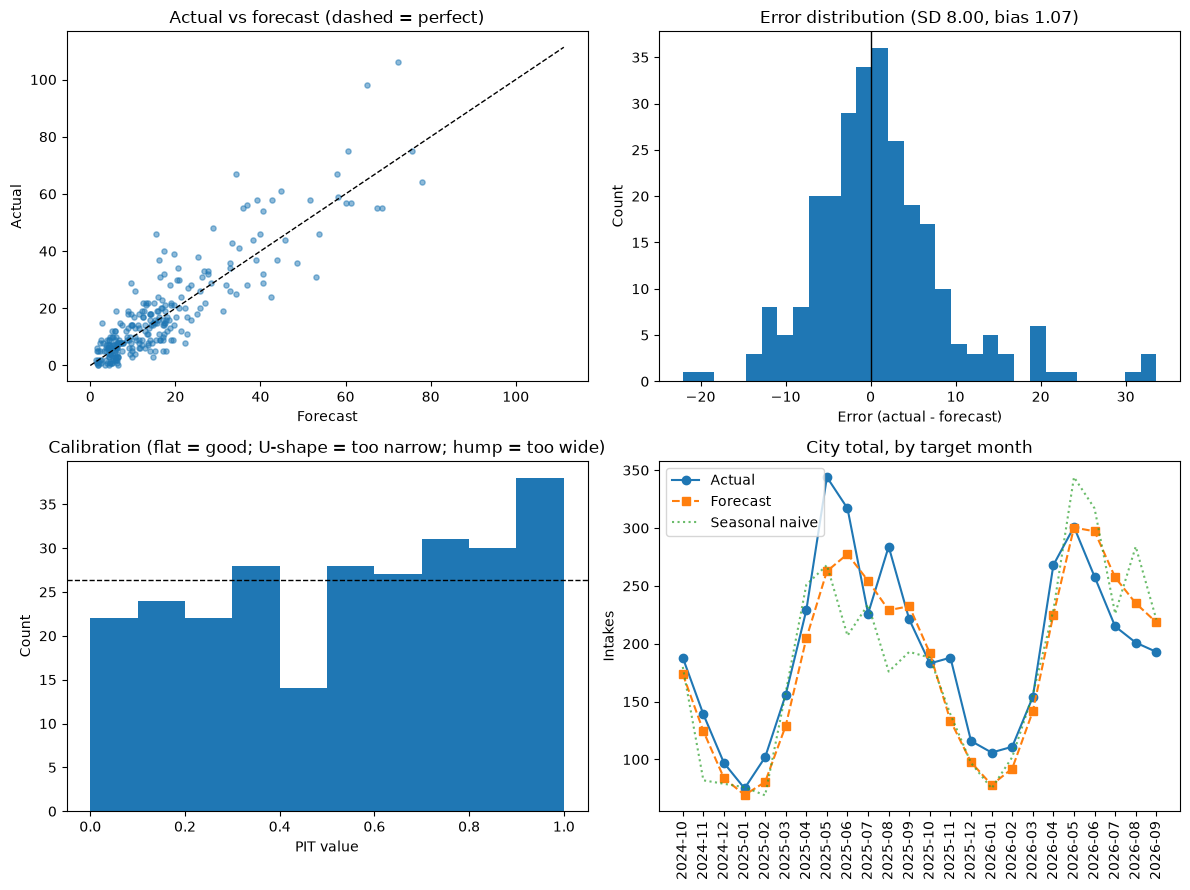


===== Horizon comparison =====
                    MAE   RMSE  SD_err   bias   WAPE  skill_vs_naive  cover80
horizon (months)                                                             
1                 5.649  8.055   7.999  1.067  0.319           0.314    0.807
3                 5.713  8.153   8.062  1.309  0.323           0.307    0.803
6                 5.826  8.245   8.182  1.131  0.329           0.293    0.803
12                5.672  8.081   7.880  1.856  0.320           0.312    0.830


In [123]:
R1 = backtest(counts, h=1)
results = evaluate(R1, h=1)

print("\n===== Horizon comparison =====")
print(compare_horizons(counts))

In [124]:
import json
import os
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
from matplotlib import cm
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure
from matplotlib.patches import PathPatch, Rectangle
from matplotlib.path import Path
from PIL import Image
 
OUT_DIR = "forecast_outputs"
GEOJSON = "long_beach_zip_boundaries.geojson"
BLUE, ORANGE = "#1f77b4", "#ff7f0e"
OUTLOOK_MONTHS = 4          # months shown in the orange part of the charts
STEPS_PER_MONTH = 3         # GIF smoothness: 1 = no blending, 3-4 = smooth colour morphs
MAP_DPI = 100               # 100 -> ~800px frames; lower it if the GIF is too big
 
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(f"{OUT_DIR}/zip_charts", exist_ok=True)
os.makedirs(f"{OUT_DIR}/map_frames", exist_ok=True)

In [125]:
def forecast_path(counts, max_h=12):
    zips = list(counts.columns)
    out = []
    for h in range(1, max_h + 1):
        P = build_panel(counts, h)
        train = P.dropna(subset=["y"])
        model, alpha = fit_nb(design(train, zips), train["y"])
        new = P[P["origin"] == counts.index[-1]]
        mu = model.predict(design(new, zips)).to_numpy()
        lo, hi = nb_interval(mu, alpha)
        out.append(pd.DataFrame({"zip": new["zip"].values, "h": h,
                                 "month": counts.index[-1] + h,
                                 "forecast": mu, "lo80": lo, "hi80": hi}))
    return pd.concat(out, ignore_index=True)
 
 
fc = forecast_path(counts, 12)
print(f"Forecast covers {fc.month.min()} to {fc.month.max()} for {fc.zip.nunique()} zips")

Forecast covers 2026-10 to 2027-09 for 11 zips


In [126]:
long_csv = fc.assign(month=fc["month"].astype(str))[["zip", "month", "forecast", "lo80", "hi80"]]
long_csv = long_csv.round({"forecast": 2})
long_csv.to_csv(f"{OUT_DIR}/forecast_next_12_months_long.csv", index=False)
 
wide_csv = fc.pivot(index="zip", columns="month", values="forecast")
wide_csv.columns = [str(c) for c in wide_csv.columns]
wide_csv["total_next_12_months"] = wide_csv.sum(axis=1)
wide_csv.loc["ALL ZIPS"] = wide_csv.sum()
wide_csv.round(1).to_csv(f"{OUT_DIR}/forecast_next_12_months_wide.csv")
 
print("Saved:", f"{OUT_DIR}/forecast_next_12_months_long.csv  (zip, month, forecast, 80% interval)")
print("Saved:", f"{OUT_DIR}/forecast_next_12_months_wide.csv  (one row per zip, with 12-month total)")
 
n = OUTLOOK_MONTHS
next_n = fc[fc.h <= n].pivot(index="zip", columns="month", values="forecast")
next_n.columns = [str(c) for c in next_n.columns]
next_n[f"total_next_{n}"] = next_n.sum(axis=1)
print(f"\nExpected intakes, next {n} months:")
print(next_n.round(1).to_string())

Saved: forecast_outputs/forecast_next_12_months_long.csv  (zip, month, forecast, 80% interval)
Saved: forecast_outputs/forecast_next_12_months_wide.csv  (one row per zip, with 12-month total)

Expected intakes, next 4 months:
       2026-10  2026-11  2026-12  2027-01  total_next_4
zip                                                    
90802      8.8      7.0      4.8      3.6          24.3
90803      3.6      2.6      1.9      1.6           9.7
90804     12.5     10.0      6.7      4.9          34.1
90805     50.4     35.9     24.7     20.7         131.7
90806     25.5     18.2     12.1      9.9          65.6
90807     10.7      7.6      4.7      3.9          26.9
90808     12.0      8.9      6.0      4.8          31.8
90810     17.3     12.1      7.3      5.6          42.4
90813     31.8     23.8     15.8     12.6          84.0
90814      4.4      3.0      1.9      1.5          10.9
90815     14.6     10.7      7.9      6.8          40.0


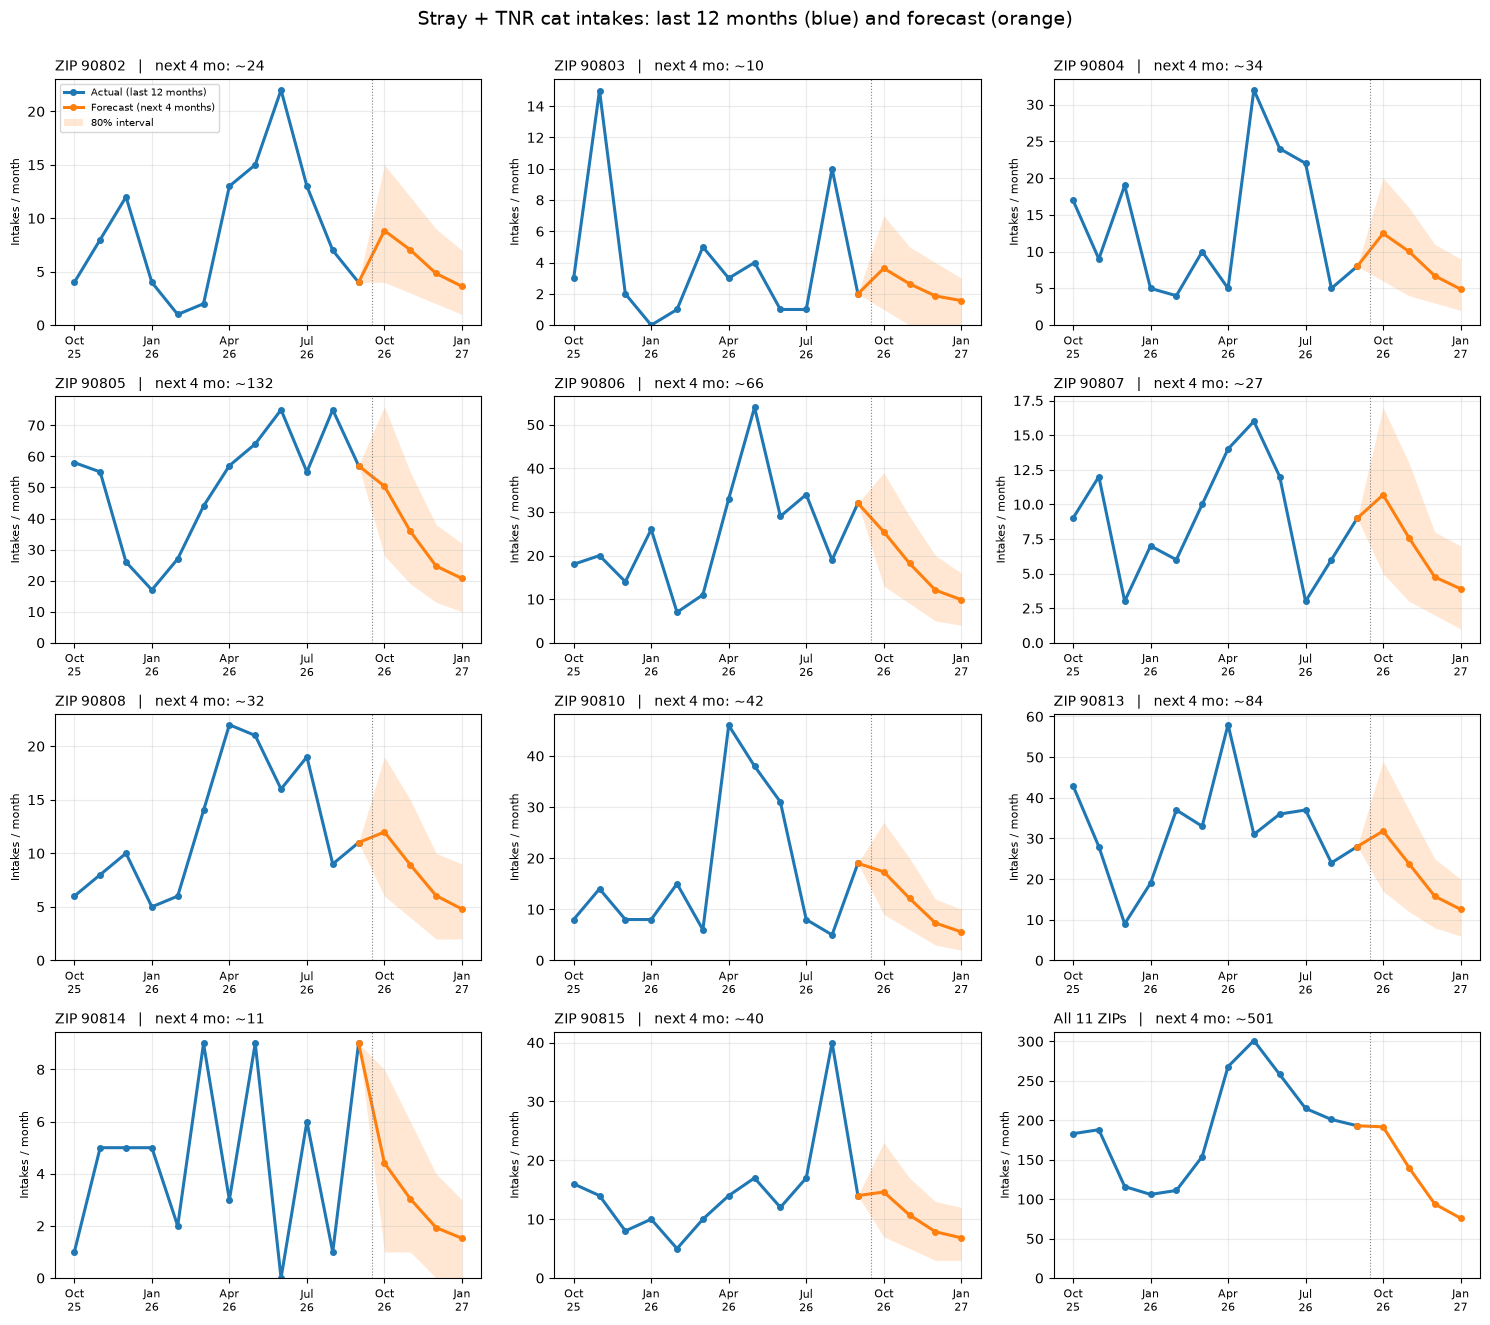

Saved forecast_outputs/outlook_all_zips.png and per-ZIP charts in forecast_outputs/zip_charts/


In [127]:
def _series_for(z, hist_n=12, fc_n=OUTLOOK_MONTHS):
    if z == "ALL":
        hs = counts.sum(axis=1).iloc[-hist_n:]
        f = fc[fc.h <= fc_n].groupby("month")[["forecast"]].sum()
        f["lo80"], f["hi80"] = np.nan, np.nan          # no interval for the total (zips are correlated)
    else:
        hs = counts[z].iloc[-hist_n:]
        f = fc[(fc.zip == z) & (fc.h <= fc_n)].set_index("month")[["forecast", "lo80", "hi80"]]
    return hs, f
 
 
def plot_outlook(ax, z, hist_n=12, fc_n=OUTLOOK_MONTHS, legend=False):
    hs, f = _series_for(z, hist_n, fc_n)
    xh = np.arange(hist_n)
    xf = np.arange(hist_n, hist_n + fc_n)
    ax.plot(xh, hs.values, color=BLUE, lw=2.2, marker="o", ms=4, label="Actual (last 12 months)")
    # start the orange line at the last blue point so the two halves join seamlessly
    xo = np.r_[hist_n - 1, xf]
    ax.plot(xo, np.r_[hs.iloc[-1], f["forecast"].values], color=ORANGE, lw=2.2,
            marker="o", ms=4, label="Forecast (next 4 months)")
    if f["lo80"].notna().all():
        ax.fill_between(xo, np.r_[hs.iloc[-1], f["lo80"].values],
                        np.r_[hs.iloc[-1], f["hi80"].values],
                        color=ORANGE, alpha=0.18, lw=0, label="80% interval")
    ax.axvline(hist_n - 0.5, color="gray", lw=0.8, ls=":")
    labels = [p.strftime("%b\n%y") for p in list(hs.index) + list(f.index)]
    ticks = list(range(0, hist_n + fc_n, 3))
    ax.set_xticks(ticks)
    ax.set_xticklabels([labels[i] for i in ticks], fontsize=8)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.25)
    name = "All 11 ZIPs" if z == "ALL" else f"ZIP {z}"
    ax.set_title(f"{name}   |   next {fc_n} mo: ~{f['forecast'].sum():.0f}", fontsize=10, loc="left")
    ax.set_ylabel("Intakes / month", fontsize=8)
    if legend:
        ax.legend(fontsize=7, loc="upper left")
 
 
panels = list(counts.columns) + ["ALL"]
ncols = 3
nrows = int(np.ceil(len(panels) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.3 * nrows))
for i, (ax, z) in enumerate(zip(axes.ravel(), panels)):
    plot_outlook(ax, z, legend=(i == 0))
for ax in axes.ravel()[len(panels):]:
    ax.axis("off")
fig.suptitle("Stray + TNR cat intakes: last 12 months (blue) and forecast (orange)", fontsize=14, y=1.0)
plt.tight_layout()
fig.savefig(f"{OUT_DIR}/outlook_all_zips.png", dpi=130, bbox_inches="tight")
plt.show()
 
for z in panels:                                   # one image per ZIP as well
    f1, a1 = plt.subplots(figsize=(7, 3.6))
    plot_outlook(a1, z, legend=True)
    f1.tight_layout()
    f1.savefig(f"{OUT_DIR}/zip_charts/outlook_{z}.png", dpi=130)
    plt.close(f1)
print(f"Saved {OUT_DIR}/outlook_all_zips.png and per-ZIP charts in {OUT_DIR}/zip_charts/")

In [128]:
def _ring_area(r):
    x, y = np.asarray(r, float).T
    return 0.5 * np.sum(x * np.roll(y, -1) - np.roll(x, -1) * y)
 
 
def _polys(geom):
    return [geom["coordinates"]] if geom["type"] == "Polygon" else geom["coordinates"]
 
 
def geom_to_path(geom):
    verts, codes = [], []
    for poly in _polys(geom):
        for k, ring in enumerate(poly):
            r = np.asarray(ring, float)
            if (k == 0) != (_ring_area(r) > 0):          # exterior counter-clockwise, holes clockwise
                r = r[::-1]
            verts.extend(r.tolist())
            codes.extend([Path.MOVETO] + [Path.LINETO] * (len(r) - 2) + [Path.CLOSEPOLY])
    return Path(np.array(verts), codes)
 
 
def label_point(geom):
    """Interior point far from the border (a good spot for a number)."""
    ring = np.asarray(max(_polys(geom), key=lambda p: abs(_ring_area(p[0])))[0], float)
    path = Path(ring)
    gx, gy = np.meshgrid(np.linspace(ring[:, 0].min(), ring[:, 0].max(), 70),
                         np.linspace(ring[:, 1].min(), ring[:, 1].max(), 70))
    pts = np.column_stack([gx.ravel(), gy.ravel()])
    pts = pts[path.contains_points(pts)]
    if len(pts) == 0:
        return ring.mean(axis=0)
    sample = ring[:: max(1, len(ring) // 400)]
    d = np.sqrt(((pts[:, None, :] - sample[None, :, :]) ** 2).sum(-1)).min(axis=1)
    return pts[d.argmax()]
 
 
with open(GEOJSON) as fh:
    gj = json.load(fh)
features = {ft["properties"]["zip"]: ft for ft in gj["features"]}
target_zips = list(counts.columns)
missing = [z for z in target_zips if z not in features]
if missing:
    raise ValueError(f"No boundary for {missing} in {GEOJSON}")
 
# 24 monthly "frames": last 12 actual months, then 12 forecast months
actual = counts.iloc[-12:]
fc_wide = fc.pivot(index="month", columns="zip", values="forecast")[target_zips]
V = np.vstack([actual[target_zips].to_numpy(float), fc_wide.to_numpy(float)])
months = list(actual.index) + list(fc_wide.index)
status = ["ACTUAL"] * 12 + ["FORECAST"] * 12
vmax = float(np.ceil(V.max()))
norm = mcolors.PowerNorm(gamma=0.6, vmin=0, vmax=vmax)   # gamma<1 keeps small ZIPs distinguishable
cmap = plt.get_cmap("plasma")

In [129]:
BG, CTX_FACE, CTX_EDGE = "#0d1117", "#1a2230", "#2b394d"
fig_map = Figure(figsize=(8, 8.6), dpi=MAP_DPI, facecolor=BG)
FigureCanvasAgg(fig_map)
ax = fig_map.add_axes([0.03, 0.12, 0.84, 0.70])
ax.set_facecolor(BG)
ax.axis("off")
 
tx = [features[z]["geometry"] for z in target_zips]
allx = np.concatenate([geom_to_path(g).vertices[:, 0] for g in tx])
ally = np.concatenate([geom_to_path(g).vertices[:, 1] for g in tx])
pad = 0.012
ax.set_xlim(allx.min() - pad, allx.max() + pad)
ax.set_ylim(ally.min() - pad, ally.max() + pad)
ax.set_aspect(1 / np.cos(np.radians(ally.mean())))
 
for z, ft in features.items():                       # faint neighbouring ZIPs for context
    if z not in target_zips:
        ax.add_patch(PathPatch(geom_to_path(ft["geometry"]), fc=CTX_FACE, ec=CTX_EDGE, lw=0.6, zorder=1))
 
patches, num_txt, zip_txt = {}, {}, {}
for z in target_zips:
    g = features[z]["geometry"]
    p = PathPatch(geom_to_path(g), fc="#444", ec="#e6edf3", lw=1.3, zorder=3)
    ax.add_patch(p)
    patches[z] = p
    lx, ly = label_point(g)
    zip_txt[z] = ax.text(lx, ly + 0.0042, z, ha="center", va="center", fontsize=7, zorder=5, color="white")
    num_txt[z] = ax.text(lx, ly - 0.0016, "", ha="center", va="center", fontsize=15,
                         fontweight="bold", zorder=5, color="white")
 
title = fig_map.text(0.05, 0.93, "", color="white", fontsize=26, fontweight="bold", va="center")
sub = fig_map.text(0.05, 0.885, "Stray + TNR cat intakes per month, by ZIP", color="#9fb0c3",
                   fontsize=11, va="center")
badge = fig_map.text(0.95, 0.925, "", color="white", fontsize=15, fontweight="bold",
                     ha="right", va="center",
                     bbox=dict(boxstyle="round,pad=0.45", fc=BLUE, ec="none"))
note = fig_map.text(0.95, 0.88, "", color="#9fb0c3", fontsize=9, ha="right", va="center")
 
cax = fig_map.add_axes([0.89, 0.17, 0.022, 0.58])
cb = fig_map.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax)
cb.ax.tick_params(colors="#9fb0c3", labelsize=8)
cb.outline.set_edgecolor("#2b394d")
cb.set_label("intakes / month", color="#9fb0c3", fontsize=9)
 
tl = fig_map.add_axes([0.05, 0.035, 0.80, 0.045])    # timeline: blue = past, orange = predicted
tl.set_xlim(0, 24)
tl.set_ylim(0, 1)
tl.axis("off")
tl_rects = []
for i in range(24):
    r = Rectangle((i + 0.06, 0.25), 0.88, 0.5, fc=BLUE if i < 12 else ORANGE, ec="none", alpha=0.3)
    tl.add_patch(r)
    tl_rects.append(r)
tl.text(6, -0.15, "past 12 months", color=BLUE, ha="center", va="top", fontsize=8)
tl.text(18, -0.15, "predicted 12 months", color=ORANGE, ha="center", va="top", fontsize=8)
 
 
def set_frame(values, month_idx):
    for z, v in zip(target_zips, values):
        rgba = cmap(norm(v))
        patches[z].set_facecolor(rgba)
        lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
        num_txt[z].set_text(f"{int(round(v))}")
        ink = "black" if lum > 0.55 else "white"
        num_txt[z].set_color(ink)
        zip_txt[z].set_color(ink)
    is_fc = status[month_idx] == "FORECAST"
    title.set_text(months[month_idx].strftime("%b %Y"))
    badge.set_text("FORECAST" if is_fc else "ACTUAL")
    badge.get_bbox_patch().set_facecolor(ORANGE if is_fc else BLUE)
    note.set_text("model estimate" if is_fc else "recorded intakes")
    for i, r in enumerate(tl_rects):
        r.set_alpha(1.0 if i == month_idx else 0.3)
 
 
def grab():
    fig_map.canvas.draw()
    return Image.fromarray(np.asarray(fig_map.canvas.buffer_rgba())[:, :, :3].copy())

Saved forecast_outputs/intake_map.gif (2.9 MB, 70 frames)
Saved 24 monthly images in forecast_outputs/map_frames/


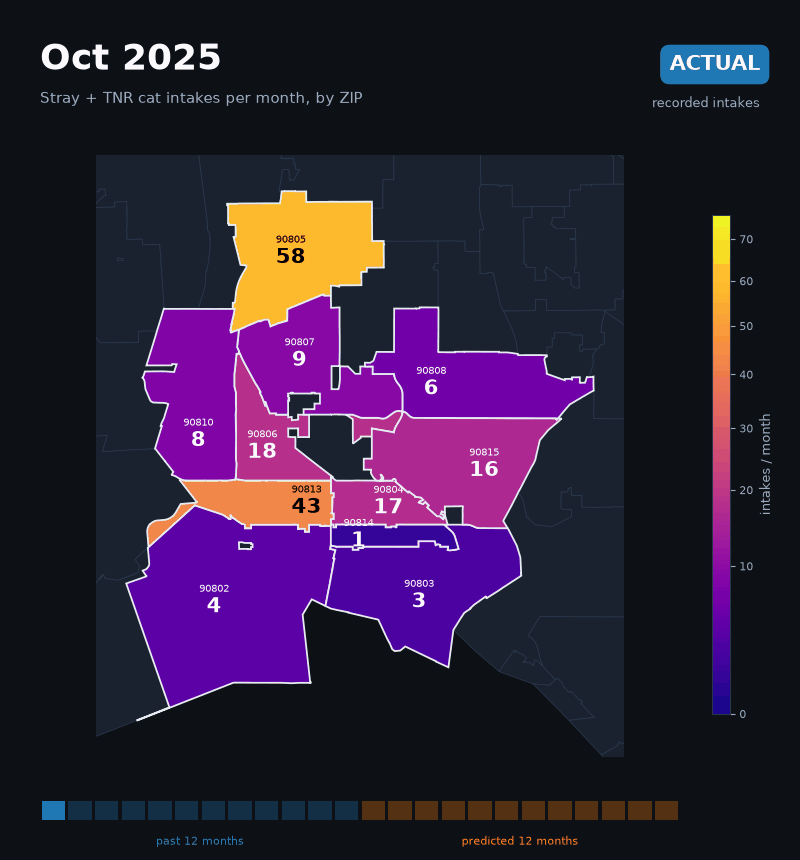

In [130]:
frames, durations = [], []
for i in range(24):
    if i > 0:                                         # blend from the previous month into this one
        for s in range(1, STEPS_PER_MONTH):
            t = s / STEPS_PER_MONTH
            set_frame(V[i - 1] * (1 - t) + V[i] * t, i)
            frames.append(grab())
            durations.append(70)
    set_frame(V[i], i)
    img = grab()
    frames.append(img)
    durations.append(1600 if i in (0, 11, 23) else 550)      # linger on the first, the "now", the last
    tag = f"{months[i]}_{status[i].lower()}"
    img.save(f"{OUT_DIR}/map_frames/map_{i + 1:02d}_{tag}.png")
 
# one shared colour palette for every frame, so the GIF doesn't flicker
sheet = Image.new("RGB", (frames[0].width, frames[0].height * 4))
for k, j in enumerate(np.linspace(0, len(frames) - 1, 4).astype(int)):
    sheet.paste(frames[j], (0, k * frames[0].height))
pal = sheet.quantize(colors=256, dither=0)
frames_p = [f.quantize(palette=pal, dither=0) for f in frames]
 
gif_path = f"{OUT_DIR}/intake_map.gif"
frames_p[0].save(gif_path, save_all=True, append_images=frames_p[1:], duration=durations,
                 loop=0, disposal=2)
print(f"Saved {gif_path} ({os.path.getsize(gif_path) / 1e6:.1f} MB, {len(frames)} frames)")
print(f"Saved 24 monthly images in {OUT_DIR}/map_frames/")
 
try:
    from IPython.display import Image as IPImage, display
    display(IPImage(filename=gif_path))
except Exception:
    pass
 